<a href="https://colab.research.google.com/github/sonalkroy15-hub/data-science-fundamental/blob/main/studentperformance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.base import TransformerMixin
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
import warnings
warnings.filterwarnings('ignore')
print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df=pd.read_csv("/content/X_test.csv")
print("Dataset uploaded successfully!")

Dataset uploaded successfully!


In [4]:
df.head()

,StudentID,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,...,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2
0,1000,GP,F,16,U,GT3,T,4,2,services,...,no,4,2,3,1,1,5,2,15,16
1,1008,GP,M,19,U,GT3,T,1,2,other,...,no,4,5,2,2,2,4,3,13,11
2,1013,GP,F,16,U,GT3,T,4,4,services,...,no,3,2,3,1,2,2,6,13,14
3,1014,GP,F,16,U,GT3,T,3,1,services,...,no,4,3,3,1,2,5,4,7,7
4,1017,GP,F,15,U,LE3,A,3,4,other,...,yes,5,3,2,1,1,1,0,10,11


In [6]:
df.tail()

,StudentID,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,...,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2
361,2032,GP,F,15,R,LE3,T,3,1,other,...,no,4,4,2,2,3,3,6,15,15
362,2034,GP,M,17,U,GT3,T,3,3,services,...,yes,4,3,4,2,3,4,12,12,12
363,2035,GP,F,16,U,GT3,T,2,3,services,...,no,2,3,1,1,1,3,2,16,16
364,2036,MS,F,16,U,GT3,T,3,1,other,...,no,3,1,3,1,3,1,0,8,6
365,2037,MS,M,18,U,GT3,T,4,4,teacher,...,no,3,2,4,1,4,2,4,15,14


In [7]:
print("Dataset shape:",df.shape)

Dataset shape: (366, 33)


In [8]:
print(df.columns.tolist())

['StudentID', 'school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


In [9]:
df.dtypes

,0
StudentID,int64
school,object
sex,object
age,int64
address,object
famsize,object
Pstatus,object
Medu,int64
Fedu,int64
Mjob,object


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   StudentID   366 non-null    int64 
 1   school      366 non-null    object
 2   sex         366 non-null    object
 3   age         366 non-null    int64 
 4   address     366 non-null    object
 5   famsize     366 non-null    object
 6   Pstatus     366 non-null    object
 7   Medu        366 non-null    int64 
 8   Fedu        366 non-null    int64 
 9   Mjob        366 non-null    object
 10  Fjob        366 non-null    object
 11  reason      366 non-null    object
 12  guardian    366 non-null    object
 13  traveltime  366 non-null    int64 
 14  studytime   366 non-null    int64 
 15  failures    366 non-null    int64 
 16  schoolsup   366 non-null    object
 17  famsup      366 non-null    object
 18  paid        366 non-null    object
 19  activities  366 non-null    object
 20  nursery   

In [12]:
df.isnull().sum()

,0
StudentID,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0


In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df=df.drop_duplicates()

In [17]:
df.describe()

,StudentID,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,1531.352459,16.737705,2.595628,2.418033,1.554645,1.934426,0.270492,3.939891,3.142077,3.185792,1.519126,2.267760,3.581967,4.139344,11.226776,11.363388
std,298.868558,1.241762,1.108069,1.106693,0.722263,0.808222,0.641534,0.898519,1.010374,1.129148,0.941241,1.281865,1.413284,5.571427,3.129260,3.265708
min,1000.000000,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,1279.500000,16.000000,2.000000,1.250000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,9.000000,9.000000
50%,1535.500000,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000
75%,1783.750000,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,4.750000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.750000,13.000000
max,2037.000000,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,40.000000,19.000000,19.000000


In [18]:
df.describe(include='object')

,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
count,366,366,366,366,366,366,366,366,366,366,366,366,366,366,366,366,366
unique,2,2,2,2,2,5,5,4,3,2,2,2,2,2,2,2,2
top,GP,F,U,GT3,T,other,other,course,mother,no,yes,no,yes,yes,yes,yes,no
freq,263,197,260,259,321,145,213,161,253,321,221,287,188,292,334,286,240


In [19]:
for col in df.columns:
  print(col,df[col].unique())

StudentID [1000 1008 1013 1014 1017 1018 1021 1024 1025 1031 1033 1035 1036 1037
 1040 1043 1046 1047 1049 1051 1053 1057 1058 1059 1060 1061 1062 1066
 1070 1071 1076 1079 1084 1085 1087 1088 1096 1098 1100 1103 1104 1114
 1119 1122 1134 1136 1139 1143 1149 1153 1155 1157 1158 1160 1164 1165
 1166 1167 1168 1169 1178 1183 1187 1192 1193 1194 1205 1211 1212 1214
 1215 1216 1217 1226 1229 1231 1232 1237 1240 1243 1244 1248 1250 1251
 1255 1258 1260 1261 1272 1273 1274 1279 1281 1286 1288 1289 1295 1298
 1300 1303 1306 1307 1310 1311 1313 1315 1316 1324 1326 1330 1331 1336
 1338 1339 1340 1343 1346 1350 1355 1356 1364 1365 1369 1371 1379 1385
 1386 1391 1399 1403 1407 1408 1413 1417 1418 1422 1423 1424 1426 1431
 1436 1437 1439 1440 1444 1447 1449 1451 1452 1458 1461 1462 1467 1469
 1472 1473 1476 1479 1482 1483 1485 1486 1487 1489 1494 1495 1497 1500
 1501 1508 1511 1512 1513 1514 1515 1517 1518 1522 1524 1527 1528 1529
 1531 1540 1542 1543 1548 1551 1556 1560 1562 1563 1565 1569 1571 1

In [20]:
df['sex'].value_counts()

,count
sex,
F,197
M,169


In [21]:
print("Average Age:",
      df['age'].mean())

Average Age: 16.737704918032787


In [23]:
df['address'].value_counts()

,count
address,
U,260
R,106


In [24]:
print("Average study Time:",
      df['studytime'].mean())

Average study Time: 1.9344262295081966


In [25]:
df['Mjob'].value_counts()

,count
Mjob,
other,145
at_home,76
services,74
teacher,41
health,30


In [26]:
df['Fjob'].value_counts()

,count
Fjob,
other,213
services,96
teacher,22
at_home,20
health,15


In [27]:
df['schoolsup'].value_counts()

,count
schoolsup,
no,321
yes,45


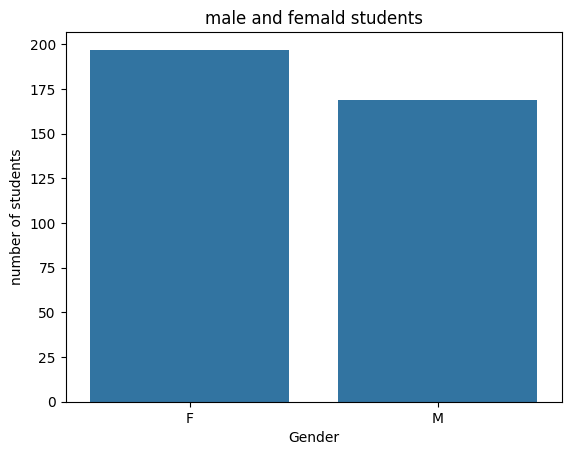

In [28]:
sns.countplot(data=df,x='sex')
plt.title('male and femald students')
plt.xlabel('Gender')
plt.ylabel('number of students')
plt.show()

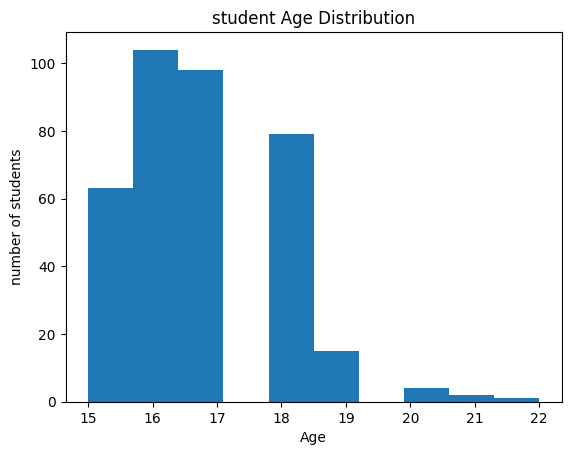

In [30]:
plt.hist(df['age'],bins=10)
plt.title('student Age Distribution')
plt.xlabel('Age')
plt.ylabel('number of students')
plt.show()

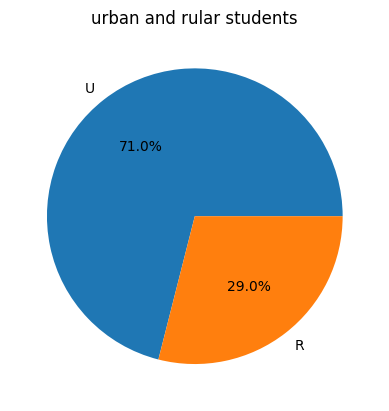

In [32]:
df['address'].value_counts().plot(kind='pie',
                                  autopct='%1.1f%%')
plt.title('urban and rular students')
plt.ylabel('')
plt.show()

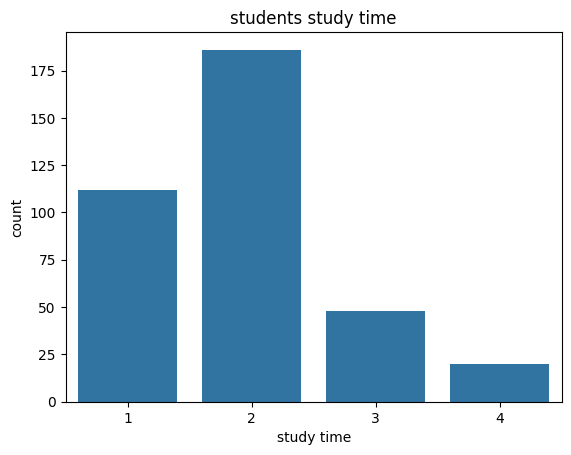

In [33]:
sns.countplot(data=df,x='studytime')
plt.title('students study time')
plt.xlabel('study time')
plt.ylabel('count')
plt.show()

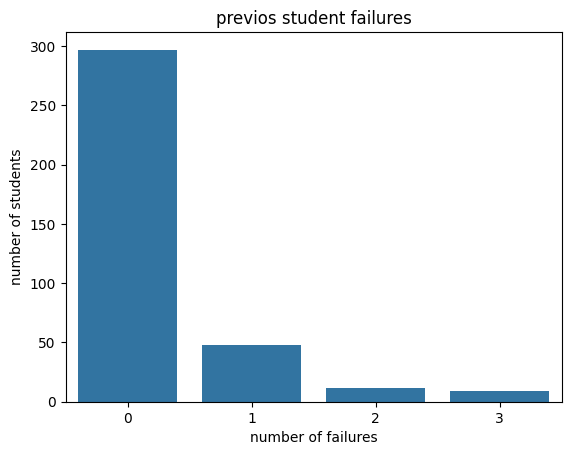

In [34]:
sns.countplot(data=df,x='failures')
plt.title('previos student failures')
plt.xlabel('number of failures')
plt.ylabel('number of students')
plt.show()